In [1]:
import pandas as pd
import os
import nibabel as nib
import numpy as np
# from pytorch_msssim import ssim, ms_ssim
from skimage.metrics import structural_similarity as ssim
# psnr
from skimage.metrics import peak_signal_noise_ratio as psnr
import re
import matplotlib.pyplot as plt 
import torch
from tqdm import tqdm
import ants

In [2]:
csv_file = "/scratch/anirudhkaushik/ADNI1_Complete_DataSplits.csv"
df = pd.read_csv(csv_file)
df = df[df[f'fold_1'] == 'test'].reset_index(drop=True)

df['Acq Date'] = pd.to_datetime(df['Acq Date'])
df = df.sort_values(by=['Subject', 'Visit', 'Acq Date']).drop_duplicates(subset=['Subject', 'Visit'], keep='last')
# Grouping subjects
subject_groups = df.groupby('Subject').apply(lambda x: x.sort_values(by='Acq Date'))
subjects = list(subject_groups.index.levels[0])


In [3]:
# load the image

noder_dir = "/scratch/anirudhkaushik/NODER_result/"




In [12]:
# calculate ssim and ms_ssim    
def get_metrics(target_img, noder_img):
    target_img_data = target_img
    noder_img_data = noder_img

    # target_img_data = (target_img_data - target_img_data.min())/ (target_img_data.max() - target_img_data.min())
    # noder_img_data = (noder_img_data - noder_img_data.min())/ (noder_img_data.max() - noder_img_data.min())
    # target_img_data = target_img_data.astype(np.float32)
    # noder_img_data = noder_img_data.astype(np.float32)


    ssim_value = ssim(target_img_data, noder_img_data, data_range=1, multichannel=False)
    psnr_value = psnr(target_img_data, noder_img_data, data_range=1)
    return ssim_value, psnr_value

def load_nii(imgPath,padding = (128, 128, 128)):
    img_data = nib.load(imgPath).get_fdata()
    if img_data.ndim == 4:
        img_data = img_data.squeeze(0)
    img_data,_ = pad(img_data,shape=padding)
    img_data = preprocess_Normalizition(img_data)

    return img_data

def pad(array, shape):
    """
    Zero-pads an array to a given shape. Returns the padded array and crop slices.
    """
    if array.shape == tuple(shape):
        return array, ...

    padded = np.zeros(shape, dtype=array.dtype)
    offsets = [int((p - v) / 2) for p, v in zip(shape, array.shape)]
    slices = tuple([slice(offset, l + offset) for offset, l in zip(offsets, array.shape)])
    padded[slices] = array

    return padded, slices

def preprocess_Normalizition(img,method="min_max"):
    img=img.astype(np.float32)
    if method=="min_max":
        front_img=img[img>0]
        min_value=np.min(front_img)
        max_value=np.max(front_img)
        img=(img-min_value)/(max_value-min_value)
        img[img<0]=0.0
    elif method=="mean":
        front_img=img[img>0]
        mean_value=np.mean(front_img)
        std_value=np.std(front_img)
        img=(img-mean_value)/std_value
    return img


In [13]:
# all_noder_files = os.listdir(noder_dir)
# synbadd_dir = "/scratch/anirudhkaushik/SYNBADD_Qualitative_1/SYNBADD_128_6_5e-05_0.0_2025-04-16_04-59-48_ADNI_all_longitudinal_FinalVAETransformer_Vanilla_Fold1/"
# all_synbadd_files = os.listdir(synbadd_dir)
# ssim_values = []
# psnr_values = []

# # filess = "/scratch/anirudhkaushik/NODER_result/ADNI_005_S_1341_MR_MPR__GradWarp__B1_Correction__N3__Scaled_Br_1739948564_S40875_I78709_padded_transposed_padded_transposed.nii.gz"

# for i, file in enumerate(tqdm(all_noder_files )):
#     if not file.endswith('.nii.gz'):
#         continue
#     image_id = re.search(r'S\d+_I\d+', file)
#     image_id = image_id.group(0)
#     # find corresponding image in df File_Path using contains
#     file_path = df[df['File_Path'].str.contains(image_id)]['File_Path'].values[0]
#     # find corresponding image in synbadd
#     synbadd_file_path = [f for f in all_synbadd_files if image_id in f][0]
#     synbadd_field_path = [f for f in all_synbadd_files if image_id in f][1]

#     target_img = load_nii(file_path)
#     noder_img = load_nii(os.path.join(noder_dir, file))
#     synbadd_img = load_nii(os.path.join(synbadd_dir, synbadd_file_path))
#     synbadd_field_img = nib.load(os.path.join(synbadd_dir, synbadd_field_path)).get_fdata().transpose(1,2,3,0)

#     ssim_value, psnr_value = get_metrics(target_img, noder_img)
#     ssim_values.append(ssim_value)
#     psnr_values.append(psnr_value)

#     synbadd_ssim_value, synbadd_psnr_value = get_metrics(target_img, synbadd_img)
#     print(f"Image ID: {image_id}, Noder SSIM: {ssim_value:.4f}, Noder PSNR: {psnr_value:.4f}, SynBADD SSIM: {synbadd_ssim_value:.4f}, SynBADD PSNR: {synbadd_psnr_value:.4f}")

#     plt.figure(figsize=(15, 5))
#     plt.subplot(1,3, 1)
#     plt.imshow(target_img[:, :, 64], cmap='gray')
#     plt.axis('off')

#     plt.title('Target Image')
#     plt.subplot(1,3, 2)
#     plt.imshow(noder_img[:, :, 64], cmap='gray')
#     plt.axis('off')

#     plt.title('NODER Image')
#     plt.subplot(1,3, 3)
#     plt.imshow(synbadd_img[:, :, 64], cmap='gray')
#     plt.axis('off')

#     plt.title('SynBADD Image')

#     plt.show()

    
#     # plot the corresponding deformation field
#     # print(synbadd_field_img.shape)
#     # for c in range(synbadd_field_img.shape[-1]):
#     #     plt.subplot(1, synbadd_field_img.shape[-1], c + 1)
#     #     plt.title(f'SynBADD Field {c}')
#     #     plt.axis('off')
#     #     plt.imshow(synbadd_field_img[:, :, 64, c], cmap = 'seismic', vmin = -1.0, vmax = 1.0, origin = 'lower')

#     diff_noder = target_img - noder_img
#     diff_synbadd = target_img - synbadd_img

#     # Create figure with shared colorbar and equal subplot sizes
#     fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)

#     # Plot the first image
#     im1 = ax1.imshow(diff_noder[:, :, 64], cmap='seismic', vmin=-1.0, vmax=1.0, origin='lower')
#     ax1.set_axis_off()
#     ax1.set_title('NODER Diff Image')

#     # Plot the second image
#     im2 = ax2.imshow(diff_synbadd[:, :, 64], cmap='seismic', vmin=-1.0, vmax=1.0, origin='lower')
#     ax2.set_axis_off()
#     ax2.set_title('SynBADD Diff Image')

#     # Add a single colorbar on the right side
#     cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # [left, bottom, width, height]
#     cbar = fig.colorbar(im2, cax=cbar_ax)
#     cbar.set_label('Difference Value', fontsize=12)

#     # Make the two images touch each other with zero spacing
#     plt.subplots_adjust(wspace=0, hspace=0, left=0.01, right=0.9)

#     # Ensure both images have the same aspect ratio and scaling
#     ax1.set_aspect('equal')
#     ax2.set_aspect('equal')

#     plt.tight_layout(rect=[0, 0, 0.9, 1])  # Adjust layout but leave room for colorbar
#     plt.show()
#     break
        




    

In [14]:
# Define function to calculate Dice score
def dice_score(pred, target):
    intersection = np.sum(pred * target)
    return (2.0 * intersection) / (np.sum(pred) + np.sum(target) + 1e-6)  # Add small epsilon to avoid division by zero

# Function to extract specific region from segmentation mask
def extract_region(seg_data, region_ids):
    """
    Extract binary mask for specific region(s)
    
    Args:
        seg_data: 3D numpy array of segmentation data
        region_ids: List of region IDs to extract
        
    Returns:
        Binary mask where the specified regions are 1, everything else is 0
    """
    mask = np.zeros_like(seg_data)
    for region_id in region_ids:
        mask[seg_data == region_id] = 1
    return mask

# Update your existing code with the following additions:
all_noder_files = os.listdir(noder_dir)
synbadd_dir = "/scratch/anirudhkaushik/SYNBADD_Qualitative_1/SYNBADD_128_6_5e-05_0.0_2025-04-16_04-59-48_ADNI_all_longitudinal_FinalVAETransformer_Vanilla_Fold1/"
all_synbadd_files = os.listdir(synbadd_dir)
ssim_values = []
psnr_values = []

synbadd_ssim_values = []
synbadd_psnr_values = []

mask_dir = "/scratch/anirudhkaushik/ADNI_Resized_Registered_segs/"
all_mask_files = os.listdir(mask_dir)

# Define regions of interest and their corresponding IDs in the DKT atlas
regions = {
    'hippocampus': [17, 53],  # Left and right hippocampus
    'parahippocampal': [1016, 2016],  # Left and right parahippocampal gyrus
    'third_ventricle': [14]  # Third ventricle
}

# Initialize dictionaries to store Dice scores
noder_dice_scores = {region: [] for region in regions}
synbadd_dice_scores = {region: [] for region in regions}

for i, file in enumerate(tqdm(all_noder_files)):
    if not file.endswith('.nii.gz'):
        continue
    
    image_id = re.search(r'S\d+_I\d+', file)
    if not image_id:
        continue
    image_id = image_id.group(0)
    
    # Find corresponding image in df File_Path using contains
    file_path = df[df['File_Path'].str.contains(image_id)]['File_Path'].values[0]
    
    # Find corresponding image in synbadd
    synbadd_files = [f for f in all_synbadd_files if image_id in f]
    if len(synbadd_files) < 2:
        print(f"Skipping {image_id}: Missing SynBADD files")
        continue
    
    for k in synbadd_files:
        if "_synthetic.nii.gz" in k:
            synbadd_file_path = k
        elif "_synthetic_field.nii.gz" in k:
            synbadd_field_path = k

    # Find corresponding mask
    mask_files = [f for f in all_mask_files if image_id in f]
    seg_file = None
    for k in mask_files:
        if '_aparc.DKTatlas+aseg.deep_resized_IPL_padded.nii.gz' in k:
            seg_file = k
            break
    
    if not seg_file:
        print(f"Skipping {image_id}: Missing segmentation file")
        continue

    # Load images
    target_img_data = load_nii(file_path)
    noder_img_data = load_nii(os.path.join(noder_dir, file))
    synbadd_img_data = load_nii(os.path.join(synbadd_dir, synbadd_file_path))
    
    # Load segmentation mask
    mask_nib = nib.load(os.path.join(mask_dir, seg_file))
    mask_data = mask_nib.get_fdata()
    
    # Convert numpy arrays to ANTs images for registration
    target_ants = ants.from_numpy(target_img_data, origin=None, spacing=None, direction=None)
    noder_ants = ants.from_numpy(noder_img_data, origin=None, spacing=None, direction=None)
    synbadd_ants = ants.from_numpy(synbadd_img_data, origin=None, spacing=None, direction=None)
    mask_ants = ants.from_numpy(mask_data, origin=None, spacing=None, direction=None)
    
    # Register NODER to target and get transformation
    print(f"Registering NODER image {image_id}...")
    noder_reg = ants.registration(
        fixed=target_ants,
        moving=noder_ants,
        type_of_transform='SyN'  # Using SyN for deformable registration
    )
    
    # Register SynBADD to target and get transformation
    print(f"Registering SynBADD image {image_id}...")
    synbadd_reg = ants.registration(
        fixed=target_ants,
        moving=synbadd_ants,
        type_of_transform='SyN'  # Using SyN for deformable registration
    )
    
    # Apply transformations to segmentation mask (with nearest neighbor interpolation)
    print(f"Applying transformations to mask {image_id}...")
    noder_mask_warped = ants.apply_transforms(
        fixed=target_ants,
        moving=mask_ants,
        transformlist=noder_reg['fwdtransforms'],
        interpolator='nearestNeighbor'
    )
    
    synbadd_mask_warped = ants.apply_transforms(
        fixed=target_ants,
        moving=mask_ants,
        transformlist=synbadd_reg['fwdtransforms'],
        interpolator='nearestNeighbor'
    )
    
    # Convert warped masks back to numpy arrays
    noder_mask_data = noder_mask_warped.numpy()
    synbadd_mask_data = synbadd_mask_warped.numpy()
    
    # Calculate Dice scores for each region of interest
    print(f"Calculating Dice scores for {image_id}...")
    for region_name, region_ids in regions.items():
        # Extract region from target mask
        target_region = extract_region(mask_data, region_ids)
        
        # Extract region from warped NODER mask
        noder_region = extract_region(noder_mask_data, region_ids)
        
        # Extract region from warped SynBADD mask
        synbadd_region = extract_region(synbadd_mask_data, region_ids)
        
        # Calculate Dice scores
        noder_dice = dice_score(noder_region, target_region)
        synbadd_dice = dice_score(synbadd_region, target_region)
        
        # Store Dice scores
        noder_dice_scores[region_name].append(noder_dice)
        synbadd_dice_scores[region_name].append(synbadd_dice)
        
        print(f"  {region_name.capitalize()} - NODER Dice: {noder_dice:.4f}, SynBADD Dice: {synbadd_dice:.4f}")
    
    # Calculate image quality metrics
    ssim_value, psnr_value = get_metrics(target_img_data, noder_img_data)
    synbadd_ssim_value, synbadd_psnr_value = get_metrics(target_img_data, synbadd_img_data)
    
    ssim_values.append(ssim_value)
    psnr_values.append(psnr_value)

    synbadd_ssim_values.append(synbadd_ssim_value)
    synbadd_psnr_values.append(synbadd_psnr_value)
    
    print(f"Image ID: {image_id}, Noder SSIM: {ssim_value:.4f}, Noder PSNR: {psnr_value:.4f}, SynBADD SSIM: {synbadd_ssim_value:.4f}, SynBADD PSNR: {synbadd_psnr_value:.4f}")
    
    # Visualization code from your original script can remain here
    # ...



  0%|          | 0/315 [00:00<?, ?it/s]

Registering NODER image S56864_I124069...
Registering SynBADD image S56864_I124069...
Applying transformations to mask S56864_I124069...
Calculating Dice scores for S56864_I124069...
  Hippocampus - NODER Dice: 0.5362, SynBADD Dice: 0.8502
  Parahippocampal - NODER Dice: 0.3144, SynBADD Dice: 0.7459
  Third_ventricle - NODER Dice: 0.5494, SynBADD Dice: 1.0000


  0%|          | 1/315 [00:08<45:47,  8.75s/it]

Image ID: S56864_I124069, Noder SSIM: 0.9461, Noder PSNR: 27.0890, SynBADD SSIM: 0.9851, SynBADD PSNR: 32.2839
Registering NODER image S61104_I134657...
Registering SynBADD image S61104_I134657...
Applying transformations to mask S61104_I134657...
Calculating Dice scores for S61104_I134657...
  Hippocampus - NODER Dice: 0.5792, SynBADD Dice: 0.8182
  Parahippocampal - NODER Dice: 0.3036, SynBADD Dice: 0.7222
  Third_ventricle - NODER Dice: 0.6942, SynBADD Dice: 0.9496


  1%|          | 2/315 [00:17<46:40,  8.95s/it]

...

Image ID: S63253_I137298, Noder SSIM: 0.9712, Noder PSNR: 30.3792, SynBADD SSIM: 0.9936, SynBADD PSNR: 36.2448
Registering NODER image S58443_I128565...
Registering SynBADD image S58443_I128565...
Applying transformations to mask S58443_I128565...
Calculating Dice scores for S58443_I128565...
  Hippocampus - NODER Dice: 1.0000, SynBADD Dice: 0.9878
  Parahippocampal - NODER Dice: 1.0000, SynBADD Dice: 0.9792
  Third_ventricle - NODER Dice: 1.0000, SynBADD Dice: 1.0000


 10%|▉         | 31/315 [04:44<43:13,  9.13s/it]

Image ID: S58443_I128565, Noder SSIM: 0.9711, Noder PSNR: 25.4361, SynBADD SSIM: 0.9640, SynBADD PSNR: 24.9172
Registering NODER image S62803_I136220...


 10%|▉         | 31/315 [04:49<44:08,  9.33s/it]


KeyboardInterrupt: 

Min PSNR: 21.019627149629493
Max PSNR: 39.306336903546615
Avg PSNR: 28.320796189103554
Min SSIM: 0.8651509739771299
Max SSIM: 0.995289413731691
Avg SSIM: 0.9491864049450273


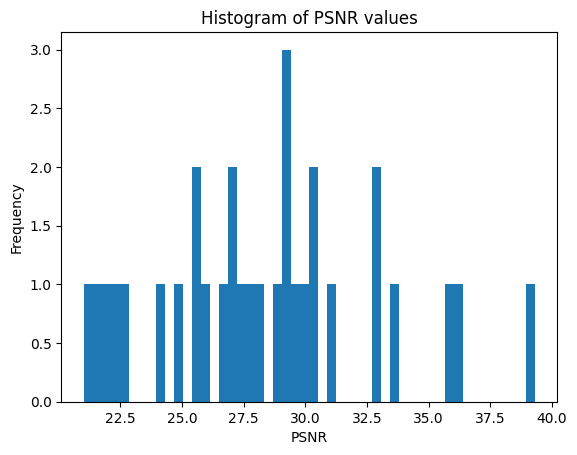

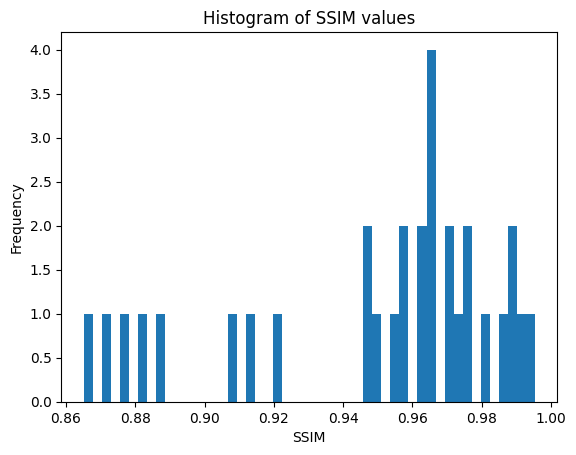


Average Dice Scores:
Hippocampus:
  NODER: 0.6668
  SynBADD: 0.8851
Parahippocampal:
  NODER: 0.5600
  SynBADD: 0.8338
Third_ventricle:
  NODER: 0.8071
  SynBADD: 0.9487


In [15]:
# print min, max and avg psnr and ssim
print(f"Min PSNR: {min(psnr_values)}")
print(f"Max PSNR: {max(psnr_values)}")
print(f"Avg PSNR: {np.mean(psnr_values)}")
print(f"Min SSIM: {min(ssim_values)}")
print(f"Max SSIM: {max(ssim_values)}")
print(f"Avg SSIM: {np.mean(ssim_values)}")
# plot histogram of psnr values

plt.hist(psnr_values, bins=50)
plt.xlabel('PSNR')
plt.ylabel('Frequency')
plt.title('Histogram of PSNR values')
plt.savefig('psnr_histogram.png')
plt.show()
# plot histogram of ssim values
plt.hist(ssim_values, bins=50)
plt.xlabel('SSIM')
plt.ylabel('Frequency')
plt.title('Histogram of SSIM values')
plt.savefig('ssim_histogram.png')
plt.show()


# After processing all images, calculate average Dice scores
print("\nAverage Dice Scores:")
for region_name in regions:
    avg_noder_dice = np.mean(noder_dice_scores[region_name])
    avg_synbadd_dice = np.mean(synbadd_dice_scores[region_name])
    print(f"{region_name.capitalize()}:")
    print(f"  NODER: {avg_noder_dice:.4f}")
    print(f"  SynBADD: {avg_synbadd_dice:.4f}")

In [8]:
remind_dir = "/scratch/anirudhkaushik/interpolated_results/"
all_remind_files = os.listdir(remind_dir)
ssim_values = []
psnr_values = []

# filess = "/scratch/anirudhkaushik/NODER_result/ADNI_005_S_1341_MR_MPR__GradWarp__B1_Correction__N3__Scaled_Br_1739948564_S40875_I78709_padded_transposed_padded_transposed.nii.gz"
failed_files = 0
for i, file in enumerate(tqdm(all_remind_files )):
    if not file.endswith('.nii.gz'):
        continue
    image_id = re.search(r'S\d+_I\d+', file)
    image_id = image_id.group(0)
    # find corresponding image in df File_Path using contains
    try:
        file_path = df[df['File_Path'].str.contains(image_id)]['File_Path'].values[0]
        target_img = load_nii(file_path)
        remind_img = load_nii(os.path.join(remind_dir, file))

        ssim_value, psnr_value = get_metrics(target_img, remind_img)
        ssim_values.append(ssim_value)
        psnr_values.append(psnr_value)
    except: 
        failed_files += 1
        break


    # plt.subplot(1,2, 1)
    # plt.imshow(target_img[:, :, 64], cmap='gray')

    # plt.title('Target Image')
    # plt.subplot(1,2, 2)
    # plt.imshow(noder_img[:, :, 64], cmap='gray')

    # plt.title('ReMiND Image')

    # plt.show()
    # break
print(f"Number of failed files: {failed_files}")




    

  8%|▊         | 24/315 [00:07<01:33,  3.10it/s]

Number of failed files: 1


Min PSNR: 6.18692535852545
Max PSNR: 9.86604576168257
Avg PSNR: 8.295639913320189
Min SSIM: 0.0009219042826617515
Max SSIM: 0.007851533191542345
Avg SSIM: 0.004782011768621085


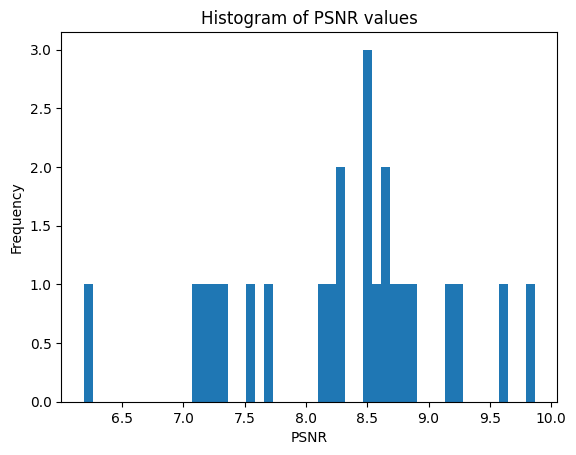

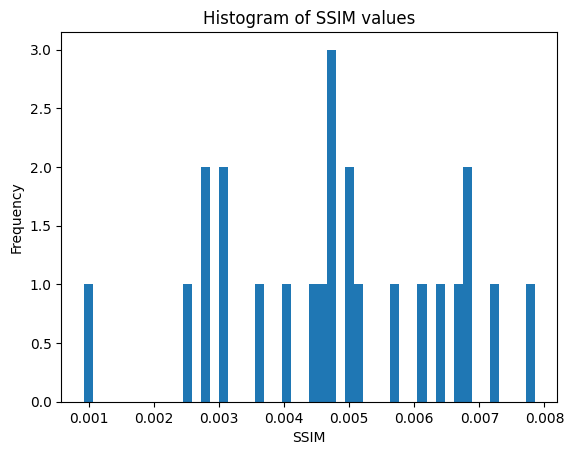

In [9]:
# print min, max and avg psnr and ssim
print(f"Min PSNR: {min(psnr_values)}")
print(f"Max PSNR: {max(psnr_values)}")
print(f"Avg PSNR: {np.mean(psnr_values)}")
print(f"Min SSIM: {min(ssim_values)}")
print(f"Max SSIM: {max(ssim_values)}")
print(f"Avg SSIM: {np.mean(ssim_values)}")
# plot histogram of psnr values

plt.hist(psnr_values, bins=50)
plt.xlabel('PSNR')
plt.ylabel('Frequency')
plt.title('Histogram of PSNR values')
plt.savefig('psnr_histogram.png')
plt.show()
# plot histogram of ssim values
plt.hist(ssim_values, bins=50)
plt.xlabel('SSIM')
plt.ylabel('Frequency')
plt.title('Histogram of SSIM values')
plt.savefig('ssim_histogram.png')
plt.show()
